# Normalization and Model Performance: Logistic Regression & Linear Regression

**Course:** AI & Data Science  |  **Time:** ~60 min

### Learning objectives
1. Use `StandardScaler` and `MinMaxScaler` correctly (fit on train, transform train and test).
2. Show how normalization affects a **binary classifier (logistic regression)**: convergence, accuracy, regularization, gradient descent.
3. Show how normalization affects **linear regression**: predictions, coefficient interpretation, gradient descent, Ridge, conditioning.
4. Avoid **data leakage** when scaling.

### How to use this notebook
- Cells containing **`___`** are **blanks for you to fill in**. Replace each `___` with the correct code.
- Run cells top to bottom. A cell with an unfilled blank raises an error; that is expected.
- Where you see **Your answer:**, write a short answer in the text cell below.

In [ ]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import accuracy_score, log_loss, r2_score

np.random.seed(42)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.figsize"] = (8, 4)
print("Setup complete")

Setup complete


---
## Part 1. The tools

A tiny dataset whose features live on very different scales:

In [ ]:
df = pd.DataFrame({
    "age":          [22, 35, 47, 52, 29],
    "salary":       [28000, 54000, 81000, 120000, 39000],
    "num_children": [0, 1, 2, 3, 0],
})
df

,age,salary,num_children
0,22,28000,0
1,35,54000,1
2,47,81000,2
3,52,120000,3
4,29,39000,0


**Standardization (z-score):** $z = \frac{x - \mu}{\sigma}$, giving mean 0 and standard deviation 1 per feature.

**Min-max scaling:** $x' = \frac{x - x_{min}}{x_{max} - x_{min}}$, giving values in [0, 1].

**Task:** apply both scalers to `df`.

In [ ]:
std_scaler = StandardScaler() # Create a standard scaler instance to scale df
X_std = std_scaler.fit_transform(df) # Obtains standardized x

mm_scaler = MinMaxScaler() # Create a min max scaler to scale df
X_mm = mm_scaler.fit_transform(df) # To obtain standardized x

X_std_df = pd.DataFrame(X_std, columns=df.columns)
print("standardized mean:", X_std_df.mean().round(6).to_dict())
print("standardized std :", X_std_df.std(ddof=0).round(6).to_dict())
print("min-max range    :", X_mm.min(axis=0), X_mm.max(axis=0))


# mean of scaled data = 0
# sd of scaled data = 1 using standard scaler while in min-max range it will be 0-1

standardized mean: {'age': 0.0, 'salary': 0.0, 'num_children': 0.0}
standardized std : {'age': 1.0, 'salary': 1.0, 'num_children': 1.0}
min-max range    : [0. 0. 0.] [1. 1. 1.]


**Check by hand.** `StandardScaler` is just a formula (it uses the *population* std, `ddof=0`).

In [ ]:
manual_z = (df - df.mean()) / df.std(ddof=0)
print("Manual result matches StandardScaler:", np.allclose(manual_z.values, X_std))

Manual result matches StandardScaler: True


---
## Part 2. Logistic regression (binary classification)

Dataset: Wisconsin breast cancer (569 patients, 30 numeric features, target: benign = 1 / malignant = 0).

                             min        max      std
worst area              185.2000 4,254.0000 569.3570
mean area               143.5000 2,501.0000 351.9141
area error                6.8020   542.2000  45.4910
concave points error      0.0000     0.0528   0.0062
smoothness error          0.0017     0.0311   0.0030
fractal dimension error   0.0009     0.0298   0.0026


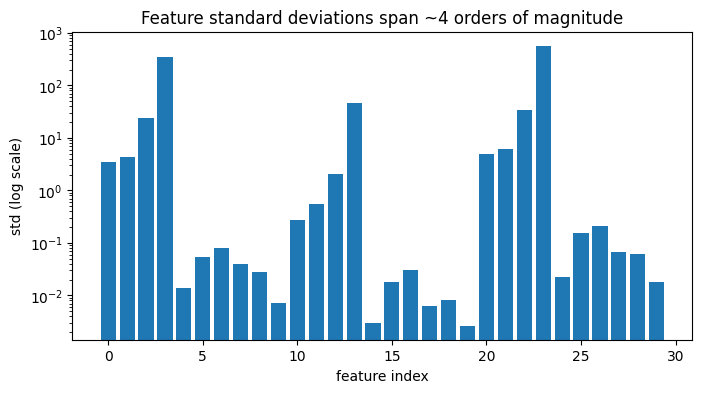

In [ ]:
data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target

print(X.describe().T[["min", "max", "std"]].sort_values("std", ascending=False).iloc[[0, 1, 2, -3, -2, -1]])

fig, ax = plt.subplots()
ax.bar(range(X.shape[1]), X.std().values)
ax.set_yscale("log"); ax.set_xlabel("feature index"); ax.set_ylabel("std (log scale)")
ax.set_title("Feature standard deviations span ~4 orders of magnitude")
plt.show()

# Load data - outputs indicate we need to standardize

### 2.1 Split first, scale second

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # learn mean/std from TRAIN
X_test_s  = scaler.transform(X_test)        # reuse the SAME mean/std on TEST- creates a transformation using other parameters in the training set
print(X_train.shape, X_test.shape)

(426, 30) (143, 30)


### 2.2 Convergence: does the solver even finish?
Logistic regression has no closed-form solution; it is fitted by an iterative optimizer. With scikit-learn's default `max_iter=100`, see what happens on raw vs scaled data.

In [ ]:
def fit_and_report(Xtr, Xte, label, max_iter=100):
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        model = LogisticRegression(max_iter=max_iter).fit(Xtr, y_train) # *** create logistic reg + train
    converged = len(caught) == 0
    acc = accuracy_score(y_test, model.predict(Xte)) #*** to predict the true y
    ll  = log_loss(y_test, model.predict_proba(Xte)) # *** determines loss
    print(f"{label:8s} | converged within {max_iter} iters: {converged!s:5} | test accuracy: {acc:.4f} | test log-loss: {ll:.4f}")
    return model
# Invoke function on raw and scaled data
m_raw    = fit_and_report(X_train,   X_test,   "RAW")
m_scaled = fit_and_report(X_train_s, X_test_s, "SCALED")

RAW      | converged within 100 iters: False | test accuracy: 0.9650 | test log-loss: 0.0645
SCALED   | converged within 100 iters: False | test accuracy: 0.9790 | test log-loss: 0.0648


Now let the optimizer run as long as it needs, and count the iterations (`n_iter_`).

In [ ]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    lr_raw    = LogisticRegression(max_iter=100000).fit(X_train, y_train) # adjust number of iterations
    lr_scaled = LogisticRegression(max_iter=100000).fit(X_train_s, y_train)

print("Iterations needed (raw)   :", lr_raw.n_iter_[0]) # wrote number of iterations needed to converge
print("Iterations needed (scaled):", lr_scaled.n_iter_[0])
print("Test accuracy  raw / scaled:", accuracy_score(y_test, lr_raw.predict(X_test)),
      "/", accuracy_score(y_test, lr_scaled.predict(X_test_s)))


# we will converge in less number of iterations using scaled data so it is preferable to scale data before training

Iterations needed (raw)   : 2112
Iterations needed (scaled): 19
Test accuracy  raw / scaled: 0.965034965034965 / 0.9790209790209791


**Your answer:** Why does the optimizer need so many more iterations on the raw data? (Think about the shape of the loss surface when one feature ranges over thousands and another over fractions.)

*(write your answer here)*

---
## Part 3. Linear regression

A synthetic **house price** dataset (price in thousands of dollars):

| feature | typical range |
|---|---|
| `sqft` | 500 - 4000 |
| `bedrooms` | 1 - 5 |
| `age` (years) | 0 - 50 |
| `dist_center` (km) | 1 - 30 |
| `renovated_frac` (share renovated) | 0 - 1 |

True relationship: `price = 50 + 0.15*sqft + 10*bedrooms - 0.8*age - 2*dist_center + 60*renovated_frac + noise`

In [ ]:
rng = np.random.default_rng(0)
n = 500
house = pd.DataFrame({
    "sqft":           rng.uniform(500, 4000, n),
    "bedrooms":       rng.integers(1, 6, n).astype(float),
    "age":            rng.uniform(0, 50, n),
    "dist_center":    rng.uniform(1, 30, n),
    "renovated_frac": rng.uniform(0, 1, n),
})
price = (50 + 0.15*house.sqft + 10*house.bedrooms - 0.8*house.age
         - 2*house.dist_center + 60*house.renovated_frac + rng.normal(0, 15, n))

Xh_train, Xh_test, yh_train, yh_test = train_test_split(house, price, test_size=0.25, random_state=1)

sc_h = StandardScaler()
Xh_train_s = sc_h.fit_transform(Xh_train)
Xh_test_s  = sc_h.transform(Xh_test)
house.describe().loc[["min", "max", "std"]]

### 3.1 OLS predictions do NOT change with scaling
Ordinary least squares (`LinearRegression`) has a closed-form solution. Rescaling a feature just rescales its coefficient, so predictions are identical.

In [ ]:
ols_raw    = LinearRegression().fit(Xh_train, yh_train)
ols_scaled = LinearRegression().fit(___, yh_train)

r2_raw    = r2_score(yh_test, ols_raw.predict(Xh_test))
r2_scaled = r2_score(yh_test, ols_scaled.predict(___))
print(f"OLS test R2 raw   : {r2_raw:.6f}")
print(f"OLS test R2 scaled: {r2_scaled:.6f}")

pd.DataFrame({"coef (raw)": ols_raw.coef_, "coef (scaled)": ols_scaled.coef_}, index=house.columns)

**Your answer:** If predictions are identical, why might you still scale for linear regression? Using the *raw* coefficients, `renovated_frac` (about 60) looks hugely more important than `sqft` (about 0.15). Using the *scaled* coefficients, which feature has the largest effect per standard deviation?

*(write your answer here)*

### 3.3 Gradient descent for linear regression
Complete the gradient and update lines (loss = mean squared error).

In [ ]:
def gradient_descent(X, y, lr, n_iter):
    X = np.asarray(X, dtype=float)
    y = np.asarray(y, dtype=float)
    n, d = X.shape
    Xb = np.c_[np.ones(n), X]
    w = np.zeros(d + 1)
    losses = []
    with np.errstate(all="ignore"):
        for _ in range(n_iter):
            error = Xb @ w - y
            losses.append(np.mean(error ** 2))
            if not np.isfinite(losses[-1]):          # training exploded
                break
            grad = (2 / n) * Xb.T @ ___
            w = w - lr * ___
    return w, losses

In [ ]:
w_a, loss_a = gradient_descent(Xh_train,   yh_train, lr=0.01, n_iter=200)
w_b, loss_b = gradient_descent(Xh_train,   yh_train, lr=1e-7, n_iter=200)
w_c, loss_c = gradient_descent(Xh_train_s, yh_train, lr=0.1,  n_iter=200)

print("Raw, lr=0.01 -> iterations before exploding:", len(loss_a), "| final loss:", loss_a[-1])
print(f"Raw, lr=1e-7 -> final loss: {loss_b[-1]:,.1f}")
print(f"Scaled, lr=0.1 -> final loss: {loss_c[-1]:,.1f}")

fig, ax = plt.subplots()
ax.plot(loss_b, label="raw features, lr=1e-7 (tiny lr needed)")
ax.plot(loss_c, label="scaled features, lr=0.1")
ax.set_yscale("log"); ax.set_xlabel("iteration"); ax.set_ylabel("training MSE (log)")
ax.legend(); ax.set_title("Gradient descent convergence"); plt.show()